# PM₂.₅ Descriptive Air Quality Analysis

**Dataset:** Cleaned Afri-SET hourly air-quality dataset  
**Study period:** 1 January 2024 – 31 December 2025  
**Primary pollutant:** PM₂.₅

## Analytical objectives

1. Examine diurnal and rush-hour PM₂.₅ pollution trends.
2. Resample hourly PM₂.₅ to daily means and compare weekdays with weekends.
3. Compare daily PM₂.₅ with the **35 µg/m³ study threshold**.
4. Assess monthly and seasonal variation in PM₂.₅.

## Analytical principle

Each section follows:

**Decision → Justification → Code → Verification → Interpretation**

> **Note:** The 35 µg/m³ value is treated here as the threshold specified for this study (EPA Ghana daily expore limit). 

## Import libraries and load the cleaned dataset

### Decision
The study used the cleaned dataset as the starting point for descriptive analysis.

### Justification
The purpose of this stage is to characterize the observed PM₂.₅ pattern before feature engineering and machine-learning modelling. The methodology identifies PM₂.₅ as the primary target pollutant and uses hourly environmental observations as the core monitoring dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, kruskal
from pathlib import Path

# Configuration
#INPUT_FILE = Path("air_quality_cleaned (1).csv")
#THRESHOLD = 35.0  # µg/m³; study-specified threshold

# Load data
df = pd.read_csv("air_quality_cleaned (1).csv")

# Parse timestamp and sort chronologically
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.sort_values("date").reset_index(drop=True)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Date range:", df["date"].min(), "to", df["date"].max())
df.head()


Shape: (17544, 7)
Columns: ['date', 'PM10', 'PM2.5', 'RH', 'Temp', 'WD', 'WS']
Date range: 2024-01-01 00:00:00 to 2025-12-31 23:00:00


,date,PM10,PM2.5,RH,Temp,WD,WS
0,2024-01-01 00:00:00,223.814714,65.119368,94.011898,28.618305,260.566102,0.604881
1,2024-01-01 01:00:00,343.645577,108.224682,91.278436,28.438167,279.908333,1.534783
2,2024-01-01 02:00:00,445.856723,140.734862,91.814506,27.912167,285.158333,1.327000
3,2024-01-01 03:00:00,407.405071,138.152391,90.311495,27.583500,289.420000,1.447833
4,2024-01-01 04:00:00,400.491289,126.808911,89.519261,27.357000,286.768333,1.326083


## 0.1 Data verification

Before calculating trends, timestamp, PM₂.₅ completeness, duplicate timestamps, and chronological ordering were verify. This prevents invalid observations from silently affecting the descriptive statistics.

In [2]:
required = ["date", "PM2.5"]
missing_required = [c for c in required if c not in df.columns]

verification = pd.Series({
    "Rows": len(df),
    "Columns": df.shape[1],
    "Missing dates": df["date"].isna().sum(),
    "Missing PM₂.₅": df["PM2.5"].isna().sum(),
    "Duplicate timestamps": df["date"].duplicated().sum(),
    "Chronologically sorted": df["date"].is_monotonic_increasing,
})

print(verification)

if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")


Rows                      17544
Columns                       7
Missing dates                 0
Missing PM₂.₅                 0
Duplicate timestamps          0
Chronologically sorted     True
dtype: object


# 1. Diurnal and rush-hour PM₂.₅ analysis

### Decision
Calculate the mean, median, standard deviation, and observation count for each hour of the day.

### Justification
Hourly aggregation preserves the within-day structure of the monitoring data and allows recurrent pollution peaks to be identified. Morning and evening periods are then compared without assuming beforehand which period is more polluted.

In [3]:
hourly = (
    df.groupby(df["date"].dt.hour)["PM2.5"]
      .agg(["mean", "median", "std", "count"])
)

hourly.index.name = "hour"
hourly


,mean,median,std,count
hour,,,,
0,24.259486,16.708155,27.745010,731
1,25.020215,17.051122,27.682605,731
2,25.026619,17.104945,27.792192,731
3,24.836128,17.334537,27.387659,731
4,24.844772,17.158386,26.887340,731
5,26.216830,18.777324,26.627972,731
6,28.797061,21.539941,27.089661,731
7,30.394525,22.745099,27.638044,731
8,28.689183,21.218846,27.145895,731


In [4]:
peak_hour = int(hourly["mean"].idxmax())
peak_value = float(hourly.loc[peak_hour, "mean"])
THRESHOLD = 35 

print(f"Highest hourly mean: {peak_value:.2f} µg/m³ at {peak_hour:02d}:00")
print(f"Hours above the study threshold: {(hourly['mean'] > THRESHOLD).sum()}")


Highest hourly mean: 30.39 µg/m³ at 07:00
Hours above the study threshold: 0


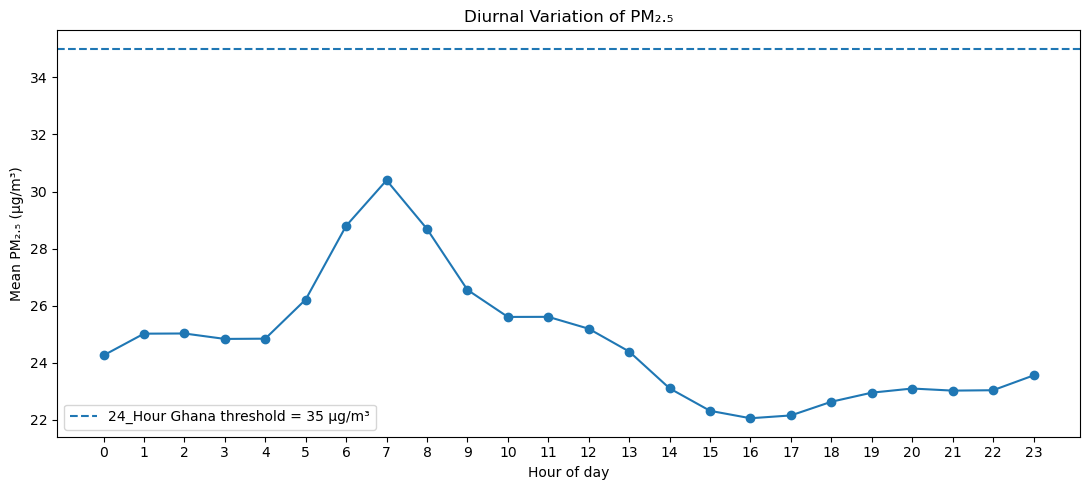

In [5]:
# Hourly analysis
plt.figure(figsize=(11, 5))
plt.plot(hourly.index, hourly["mean"], marker="o")
plt.axhline(
    THRESHOLD,
    linestyle="--",
    label=f"24_Hour Ghana threshold = {THRESHOLD:.0f} µg/m³"
)
plt.xticks(range(24))
plt.xlabel("Hour of day")
plt.ylabel("Mean PM₂.₅ (µg/m³)")
plt.title("Diurnal Variation of PM₂.₅")
plt.legend()
plt.tight_layout()
plt.show()


In [6]:
# Operational periods for descriptive comparison.
# These are analytical windows and do not establish causation.
rush = df[["date", "PM2.5"]].copy()
rush["hour"] = rush["date"].dt.hour
rush["period"] = np.select(
    [
        rush["hour"].between(6, 8),
        rush["hour"].between(16, 19)
    ],
    [
        "Morning rush (06:00–08:00)",
        "Evening period (16:00–19:00)"
    ],
    default="Other hours"
)

rush_summary = (
    rush.groupby("period")["PM2.5"]
        .agg(["mean", "median", "std", "count"])
        .round(2)
)

rush_summary


,mean,median,std,count
period,,,,
Evening period (16:00–19:00),22.45,15.59,26.01,2924
Morning rush (06:00–08:00),29.29,21.91,27.29,2193
Other hours,24.45,16.81,27.21,12427


# 2. Daily PM₂.₅ resampling

### Decision
Aggregate hourly PM₂.₅ to daily mean concentrations.

### Justification
Daily means provide a common time scale for weekday/weekend comparison and exposure-threshold assessment.

In [7]:
daily = (
    df.set_index("date")["PM2.5"]
      .resample("D")
      .mean()
      .dropna()
      .to_frame("PM2.5")
)

daily["day_type"] = np.where(
    daily.index.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

print("Number of daily observations:", len(daily))
daily.head()


Number of daily observations: 731


,PM2.5,day_type
date,,
2024-01-01,72.500052,Weekday
2024-01-02,54.145149,Weekday
2024-01-03,48.047268,Weekday
2024-01-04,41.944807,Weekday
2024-01-05,35.069646,Weekday


# 3. Weekday versus weekend comparison

### Decision
Compare daily PM₂.₅ distributions between weekdays and weekends using descriptive statistics and a Mann–Whitney U test.

### Justification
Daily PM₂.₅ can be skewed by pollution episodes, so a non-parametric comparison is appropriate for assessing whether the two day-type distributions differ without requiring normality.

In [8]:
weekday = daily.loc[daily["day_type"] == "Weekday", "PM2.5"]
weekend = daily.loc[daily["day_type"] == "Weekend", "PM2.5"]

comparison = pd.DataFrame({
    "Weekday": weekday.agg(["count", "mean", "median", "std"]),
    "Weekend": weekend.agg(["count", "mean", "median", "std"])
}).round(2)

comparison


,Weekday,Weekend
count,523.00,208.00
mean,24.40,25.53
median,17.15,17.27
std,24.18,29.71


In [9]:
u_stat, p_value = mannwhitneyu(
    weekday,
    weekend,
    alternative="two-sided"
)

print(f"Mann–Whitney U statistic: {u_stat:.2f}")
print(f"p-value: {p_value:.4f}")

if p_value < 0.05:
    print("Conclusion: statistically significant weekday/weekend difference at α = 0.05.")
else:
    print("Conclusion: no statistically significant weekday/weekend difference at α = 0.05.")


Mann–Whitney U statistic: 57079.00
p-value: 0.2970
Conclusion: no statistically significant weekday/weekend difference at α = 0.05.


C:\Users\HP\AppData\Local\Temp\ipykernel_48272\2027860294.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


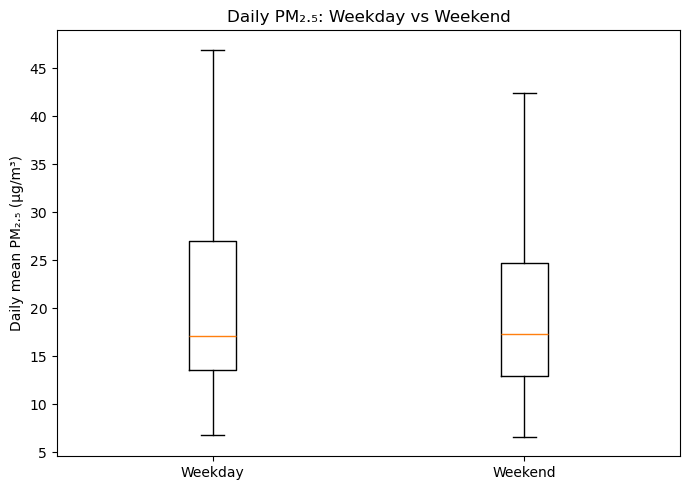

In [12]:
plt.figure(figsize=(7, 5))
plt.boxplot(
    [weekday, weekend],
    labels=["Weekday", "Weekend"],
    showfliers=False
)
plt.ylabel("Daily mean PM₂.₅ (µg/m³)")
plt.title("Daily PM₂.₅: Weekday vs Weekend")
plt.tight_layout()
plt.show()


# 4. Daily PM₂.₅ versus the 35 µg/m³ study threshold

### Decision
Classify each daily mean as either at/below or above the study threshold.

### Justification
This identifies the frequency and timing of elevated daily exposure episodes and provides a direct descriptive comparison with the threshold specified for the study.

In [10]:
daily["exceeds_threshold"] = daily["PM2.5"] > THRESHOLD

n_exceed = int(daily["exceeds_threshold"].sum())
n_days = len(daily)
pct_exceed = 100 * n_exceed / n_days

print(f"Threshold: {THRESHOLD:.1f} µg/m³")
print(f"Daily observations: {n_days}")
print(f"Days above threshold: {n_exceed}")
print(f"Percentage above threshold: {pct_exceed:.2f}%")

print("\nTop 10 daily PM₂.₅ episodes:")
display(daily.nlargest(10, "PM2.5")[["PM2.5"]].round(2))


Threshold: 35.0 µg/m³
Daily observations: 731
Days above threshold: 103
Percentage above threshold: 14.09%

Top 10 daily PM₂.₅ episodes:


,PM2.5
date,
2024-02-07,227.82
2024-02-04,211.51
2024-02-06,209.23
2024-12-22,198.61
2024-02-08,198.06
2024-02-05,187.27
2024-01-28,179.42
2024-12-23,170.13
2024-02-03,169.06


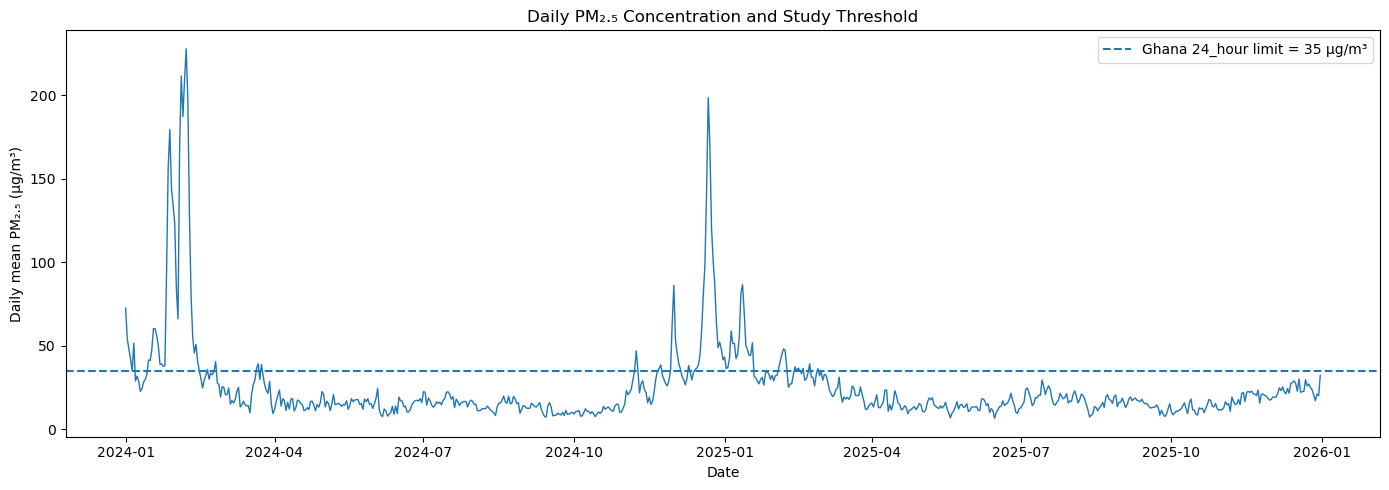

In [11]:
# Daily trend analysis
plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily["PM2.5"], linewidth=1)
plt.axhline(
    THRESHOLD,
    linestyle="--",
    label=f"Ghana 24_hour limit = {THRESHOLD:.0f} µg/m³"
)
plt.xlabel("Date")
plt.ylabel("Daily mean PM₂.₅ (µg/m³)")
plt.title("Daily PM₂.₅ Concentration and Study Threshold")
plt.legend()
plt.tight_layout()
plt.show()


# 5. Monthly and seasonal PM₂.₅ analysis

### Decision
Monthly PM₂.₅ distributions helps to identitfy the the likely environmental effect in air pollution ( dry season and wet season).

### Justification
The methodology identifies seasonal shifts, including the Harmattan period, as an important environmental consideration. Monthly analysis establishes whether a seasonal pattern exists before a broader seasonal grouping is interpreted.

**Important:** A seasonal pattern demonstrates temporal association, not causation. Wind direction, wind speed, temperature, and relative humidity should subsequently be examined to investigate possible meteorological mechanisms.

In [16]:
daily["month"] = daily.index.month

monthly = (
    daily.groupby("month")["PM2.5"]
         .agg(["mean", "median", "std", "count"])
)

monthly["percent_exceeding"] = (
    daily.groupby("month")["exceeds_threshold"].mean() * 100
)

monthly.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly.round(2)


,mean,median,std,count,percent_exceeding
Jan,51.78,42.11,32.69,62,66.13
Feb,55.73,35.04,53.17,57,50.88
Mar,21.99,20.91,7.00,62,4.84
Apr,15.10,14.50,3.56,60,0.00
May,14.52,14.71,2.79,62,0.00
Jun,13.76,13.64,3.63,60,0.00
Jul,18.30,17.39,3.65,62,0.00
Aug,15.04,15.29,3.65,62,0.00
Sep,12.92,13.15,3.38,60,0.00
Oct,11.77,11.43,2.41,62,0.00


In [17]:
# Test whether daily PM₂.₅ distributions differ across months.
month_groups = [
    group["PM2.5"].values
    for _, group in daily.groupby("month")
]

h_stat, kw_p = kruskal(*month_groups)

print(f"Kruskal–Wallis H statistic: {h_stat:.2f}")
print(f"p-value: {kw_p:.6f}")

if kw_p < 0.05:
    print("Conclusion: monthly PM₂.₅ distributions differ significantly at α = 0.05.")
else:
    print("Conclusion: no statistically significant monthly difference at α = 0.05.")


Kruskal–Wallis H statistic: 498.43
p-value: 0.000000
Conclusion: monthly PM₂.₅ distributions differ significantly at α = 0.05.


In [18]:
# Wet season ( march-oct)
# Dry season (Nov - Feb)
daily["season_period"] = np.where(
    daily.index.month.isin([11, 12, 1, 2]),
    "Nov–Feb",
    "Mar–Oct"
)

seasonal = (
    daily.groupby("season_period")["PM2.5"]
         .agg(["count", "mean", "median", "std"])
)

seasonal["percent_exceeding"] = (
    daily.groupby("season_period")["exceeds_threshold"].mean() * 100
)

seasonal.round(2)


,count,mean,median,std,percent_exceeding
season_period,,,,,
Mar–Oct,490,15.44,14.75,5.01,0.61
Nov–Feb,241,43.60,32.15,38.07,41.49


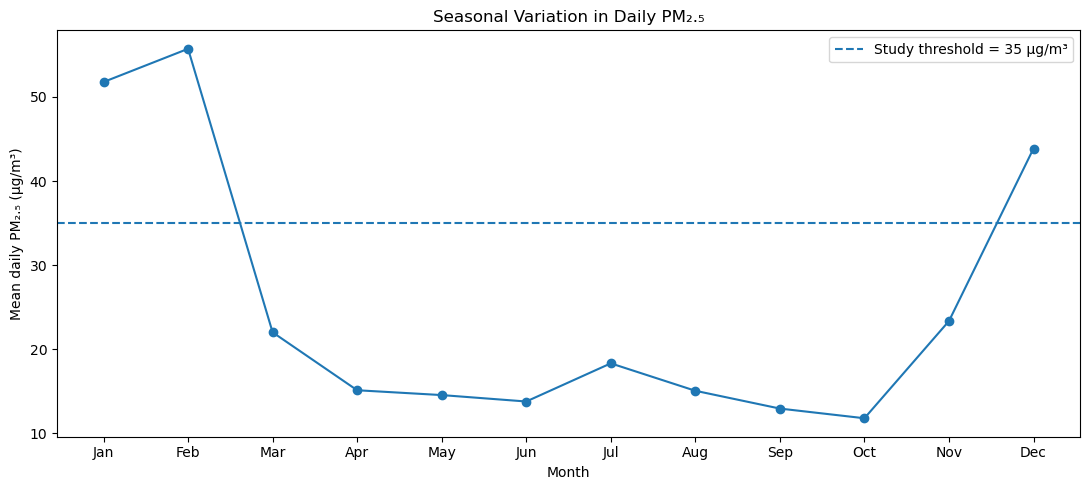

In [19]:
# Seasonal variation
plt.figure(figsize=(11, 5))
plt.plot(
    range(1, 13),
    monthly["mean"],
    marker="o"
)
plt.axhline(
    THRESHOLD,
    linestyle="--",
    label=f"Study threshold = {THRESHOLD:.0f} µg/m³"
)
plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.xlabel("Month")
plt.ylabel("Mean daily PM₂.₅ (µg/m³)")
plt.title("Seasonal Variation in Daily PM₂.₅")
plt.legend()
plt.tight_layout()
plt.show()


# 7. Export results

Tables of the analysis

In [20]:
hourly.to_csv("hourly_pm25_summary.csv")
daily.to_csv("daily_pm25_analysis.csv")
monthly.to_csv("monthly_pm25_summary.csv")
seasonal.to_csv("seasonal_pm25_summary.csv")

print("Exported:")
print("- hourly_pm25_summary.csv")
print("- daily_pm25_analysis.csv")
print("- monthly_pm25_summary.csv")
print("- seasonal_pm25_summary.csv")


Exported:
- hourly_pm25_summary.csv
- daily_pm25_analysis.csv
- monthly_pm25_summary.csv
- seasonal_pm25_summary.csv
